# Objetivo específico 3 — Insumos del tablero de monitoreo, indicadores y explicación del puntaje

**Proyecto de grado:** Modelo analítico para la detección de comportamientos atípicos de funcionarios en la aprobación de créditos del sector financiero privado colombiano (Especialización en Analítica de Datos, CUN).  
**Autores:** Ángel Antonio Rodríguez Goyo, Julio Cesar Sánchez Jiménez y Gladys Dalexa Picón Solano. **Tutor:** Andrés Felipe Solís Pino.  
**Versión del código:** v0.3 (borrador del objetivo 3) · **Semilla:** 42 · **Fase CRISP-DM:** despliegue del prototipo (fase 6).

> **Estado: borrador de trabajo.** Las decisiones marcadas como *supuesto* en la bitácora (sección 10) dependen de la respuesta del tutor y del profesor al objetivo 2 (qué modelo alimenta el tablero y si las etiquetas pueden ajustar hiperparámetros). Ninguna cifra de este cuaderno se ha copiado al informe. **No se contempla puesta en producción:** el tablero es un prototipo sobre datos sintéticos.

Este cuaderno prepara todo lo que necesita el tablero de Power BI: el **puntaje de riesgo** por solicitud y por funcionario, la **explicación de las variables que más pesan** (valores SHAP), el **modelo dimensional** (tablas de hechos y dimensiones), los **indicadores con su fórmula y su medida DAX** y la **tabla de validación de totales** que compara la fuente con el tablero. El `.pbix` lo arma el equipo con las tablas de `data/dashboard/` y la guía `dashboard/GUIA_POWER_BI.md`.

| Sección | Qué produce |
|---|---|
| 0 | Entorno, semilla y rutas |
| 1 | Puntaje de riesgo por solicitud (Isolation Forest, sin etiquetas) |
| 2 | Puntaje y nivel de riesgo por funcionario |
| 3 | Explicación del puntaje con valores SHAP |
| 4 | Modelo dimensional: tablas, relaciones y figura |
| 5 | Indicadores (KPIs): fórmula, medida DAX y valor |
| 6 | Validación de totales: fuente frente a tablero |
| 7 | Validación con la verdad sintética (solo para el prototipo) |
| 8 | Sensibilidad: variables del puntaje (8.4.3 frente a conjunto completo) |
| 9 | Exportación y comprobaciones finales |
| 10 | Bitácora de decisiones del objetivo 3 |

**Uso de las etiquetas.** No entran en ninguna tabla operativa del tablero. Viven solo en `fact_validacion_sintetica`, que alimenta la página de validación y existe únicamente porque los datos son sintéticos y la verdad es conocida.

## 0. Entorno, semilla y rutas

In [1]:
import os, sys, json, hashlib, random, platform, subprocess, warnings, pathlib
import datetime as dt

SEED = 42
VERSION = "v0.3"
REPO_URL = "https://github.com/angelgoyo/analitica_datos.git"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not pathlib.Path("src/tablero.py").exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "proyecto"], check=True)
    os.chdir("proyecto")
elif not pathlib.Path("src/tablero.py").exists() and pathlib.Path("../src/tablero.py").exists():
    os.chdir("..")

try:
    import shap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)
    import shap
try:
    import openpyxl
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openpyxl"], check=True)
    import openpyxl

ROOT = pathlib.Path.cwd()
PROC = ROOT / "data" / "processed"; DASH = ROOT / "data" / "dashboard"; FIG = ROOT / "docs" / "figuras"; TAB = ROOT / "docs" / "tablas"
RES = ROOT / "results"; RT = RES / "tables_obj3"; RT2 = RES / "tables"; GUIA = ROOT / "dashboard"
for p in (DASH, FIG, TAB, RES, RT, GUIA):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import modelado as M
from src import tablero as TB
warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_columns", 50, "display.width", 180)

RESULTADOS = {"version_codigo": VERSION, "semilla": SEED, "interpretaciones": {}}
RESULTADOS["entorno"] = {m.__name__: m.__version__ for m in (np, pd, scipy, sklearn, matplotlib, shap, openpyxl)}
RESULTADOS["entorno"]["python"] = platform.python_version()

def n(x, d=0):
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")
def minus1(s):
    """Primera letra en minúscula, sin tocar siglas ni «Z» del resto de la frase."""
    return s[:1].lower() + s[1:]
def pct(x, d=1):
    return n(100 * x, d) + " %"

AZUL, NARANJA, AGUA, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#8f8f8a", "#222222"
plt.rcParams.update({
    "font.size": 7.5, "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.labelsize": 7.5, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8f8f8a",
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.facecolor": "white", "legend.frameon": False, "text.color": TINTA, "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
})

def guardar_fig(fig, nombre):
    ruta = FIG / f"{nombre}.png"
    fig.savefig(ruta); plt.show()
    return ruta
def guardar_res(df, nombre, indice=False):
    df.to_csv(RT / f"{nombre}.csv", index=indice, encoding="utf-8-sig")
def guardar_doc(df, nombre, indice=False):
    df.to_csv(TAB / f"{nombre}.csv", index=indice, encoding="utf-8-sig")
def interpretar(clave, titulo, frases):
    """Título y frases de interpretación generadas con los resultados (nada se escribe a mano)."""
    texto = " ".join(frases)
    RESULTADOS["interpretaciones"][clave] = {"titulo": titulo, "texto": texto}
    display(Markdown(f"**{titulo}.** {texto}"))

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| shap", shap.__version__)
print("Directorio del proyecto:", ROOT)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.13.18 | scikit-learn 1.9.1 | shap 0.54.1
Directorio del proyecto: /home/claude/work/repo


## 1. Puntaje de riesgo por solicitud

Se usa **Isolation Forest** sin etiquetas, con una configuración fijada de antemano (200 árboles, 256 muestras por árbol, contaminación de 7,5 %) en lugar de los hiperparámetros del cuaderno 02, que se ajustaron con la etiqueta. Motivos: entrega un puntaje continuo, admite una explicación SHAP exacta y su desempeño se contrasta con el del cuaderno 02 en la sección 7. **Es un supuesto:** si el profesor o el tutor definen otro modelo para el tablero, se cambia `CONFIG_SOLICITUD` en `src/tablero.py` y se vuelve a ejecutar este cuaderno.

El detector se ajusta con el 70 % de entrenamiento (misma partición del cuaderno 02) y se puntúan las 9.500 solicitudes. El **puntaje de riesgo** (0 a 100) es el percentil del puntaje de anomalía frente a la distribución del entrenamiento; una solicitud queda **marcada** si supera el cuantil 92,5 % del entrenamiento (umbral de contaminación de 7,5 %). Se usan las variables del apartado 8.4.3 del informe.

In [2]:
T, CTL = TB.calcular(ROOT)
fs, valid = T["fact_solicitud"], T["fact_validacion_sintetica"]
resumen_sol = (fs.groupby("particion").agg(Solicitudes=("id_solicitud", "size"), Marcadas=("marcada", "sum"), Puntaje_promedio=("puntaje_riesgo", "mean"))
                 .assign(**{"% marcadas": lambda d: 100 * d["Marcadas"] / d["Solicitudes"]}).round(2).reset_index().rename(columns={"particion": "Conjunto", "Puntaje_promedio": "Puntaje promedio"}))
tot = pd.DataFrame([{"Conjunto": "Total", "Solicitudes": len(fs), "Marcadas": int(fs.marcada.sum()), "Puntaje promedio": round(fs.puntaje_riesgo.mean(), 2), "% marcadas": round(100 * fs.marcada.mean(), 2)}])
resumen_sol = pd.concat([resumen_sol, tot], ignore_index=True)
guardar_res(resumen_sol, "tablero_puntaje_solicitud")
display(resumen_sol.style.hide(axis="index"))
interpretar("tab_puntaje_sol", "Puntaje de riesgo por solicitud",
            [f"El umbral de marca corresponde a un puntaje de anomalía de {n(CTL['umbral_solicitud'], 3)}, el cuantil 92,5 % de las {n(CTL['n_entrenamiento'])} solicitudes de entrenamiento.",
             f"Quedan marcadas {n(int(fs.marcada.sum()))} de {n(len(fs))} solicitudes ({pct(fs.marcada.mean(), 1)}); en la prueba, {pct(fs[fs.particion == 'Prueba'].marcada.mean(), 1)} y en el entrenamiento, {pct(fs[fs.particion == 'Entrenamiento'].marcada.mean(), 1)}.",
             f"El modelo usa {len(CTL['variables_modelo'])} variables del apartado 8.4.3 y no ve la etiqueta."])

Conjunto,Solicitudes,Marcadas,Puntaje promedio,% marcadas
Entrenamiento,6650,499,50.010000,7.500000
Prueba,2850,235,51.040000,8.250000
Total,9500,734,50.320000,7.730000


**Puntaje de riesgo por solicitud.** El umbral de marca corresponde a un puntaje de anomalía de 0,506, el cuantil 92,5 % de las 6.650 solicitudes de entrenamiento. Quedan marcadas 734 de 9.500 solicitudes (7,7 %); en la prueba, 8,2 % y en el entrenamiento, 7,5 %. El modelo usa 25 variables del apartado 8.4.3 y no ve la etiqueta.

## 2. Puntaje y nivel de riesgo por funcionario

El perfil de cada funcionario se calcula con **todas sus solicitudes** (es el perfil de monitoreo) y se compara con el de sus pares mediante puntajes Z de cinco indicadores: tasa de aprobación, tasa de excepciones, monto promedio, razón monto/ingreso promedio y tiempo de respuesta promedio (apartado 8.4.4 del informe). Sobre esos cinco puntajes Z se ajusta un Isolation Forest sin etiquetas (200 árboles, contaminación de 7,5 %, la misma configuración de referencia del cuaderno 02).

El **nivel de riesgo** se define por cortes del puntaje de anomalía entre los 220 funcionarios: **Crítico** desde el cuantil 97,5 %, **Alto** desde el 92,5 % (coincide con la marca del modelo), **Medio** desde el 75 % y **Bajo** el resto. Los cortes son una propuesta de diseño para priorizar la revisión, no un resultado del modelo.

In [3]:
ff, dfun = T["fact_funcionario_riesgo"], T["dim_funcionario"]
niveles = (dfun.groupby("nivel_riesgo").size().reindex(["Crítico", "Alto", "Medio", "Bajo"]).rename("Funcionarios").reset_index().rename(columns={"nivel_riesgo": "Nivel de riesgo"}))
niveles["% de funcionarios"] = (100 * niveles["Funcionarios"] / niveles["Funcionarios"].sum()).round(1)
cortes = CTL["cortes_nivel"]
niveles["Puntaje de anomalía desde"] = [cortes["Crítico"], cortes["Alto"], cortes["Medio"], np.nan]
guardar_res(niveles, "tablero_niveles_funcionario")
display(niveles.style.hide(axis="index").format({"Puntaje de anomalía desde": "{:.3f}"}, na_rep="—"))

top = (ff.merge(dfun[["id_funcionario", "nivel_riesgo"]], on="id_funcionario")
         .merge(T["dim_variable"][["id_variable", "descripcion"]].rename(columns={"id_variable": "id_variable_1", "descripcion": "Variable que más pesa"}), on="id_variable_1")
         .sort_values("puntaje_riesgo", ascending=False).head(15))
top_tab = top[["id_funcionario", "nivel_riesgo", "puntaje_riesgo", "n_solicitudes", "tasa_aprobacion", "tasa_excepciones", "tiempo_resp_prom", "pct_marcadas", "Variable que más pesa"]].copy()
top_tab.columns = ["Funcionario", "Nivel", "Puntaje", "Solicitudes", "Tasa de aprobación", "Tasa de excepciones", "Tiempo de respuesta (días)", "% marcadas", "Variable que más pesa"]
for c in ("Tasa de aprobación", "Tasa de excepciones", "% marcadas"):
    top_tab[c] = (100 * top_tab[c]).round(1)
top_tab["Tiempo de respuesta (días)"] = top_tab["Tiempo de respuesta (días)"].round(2)
guardar_res(top_tab, "tablero_top_funcionarios")
display(top_tab.style.hide(axis="index"))
n_alto = int(dfun.nivel_riesgo.isin(["Alto", "Crítico"]).sum())
interpretar("tab_niveles", "Niveles de riesgo de los funcionarios",
            [f"De {len(dfun)} funcionarios, {n(int((dfun.nivel_riesgo == 'Crítico').sum()))} quedan en nivel crítico y {n(n_alto)} en nivel alto o crítico ({pct(n_alto / len(dfun), 1)}), que es la proporción de contaminación fijada.",
             f"El funcionario con mayor puntaje es el de identificador {top_tab.iloc[0]['Funcionario']}; la variable que más pesa en su puntaje es «{minus1(top_tab.iloc[0]['Variable que más pesa'])}».",
             "El nivel prioriza la revisión; no es una conclusión sobre la conducta del funcionario."])

Nivel de riesgo,Funcionarios,% de funcionarios,Puntaje de anomalía desde
Crítico,6,2.700000,0.590
Alto,11,5.000000,0.518
Medio,38,17.300000,0.457
Bajo,165,75.000000,—


Funcionario,Nivel,Puntaje,Solicitudes,Tasa de aprobación,Tasa de excepciones,Tiempo de respuesta (días),% marcadas,Variable que más pesa
95,Crítico,100.000000,46,100.000000,34.800000,12.830000,34.800000,Tasa de aprobación frente a sus pares (Z)
52,Crítico,99.550000,42,100.000000,59.500000,10.740000,45.200000,Tasa de excepciones frente a sus pares (Z)
23,Crítico,99.090000,42,100.000000,61.900000,8.570000,40.500000,Tasa de excepciones frente a sus pares (Z)
197,Crítico,98.640000,46,100.000000,58.700000,7.570000,41.300000,Tasa de excepciones frente a sus pares (Z)
139,Crítico,98.180000,39,97.400000,48.700000,7.720000,35.900000,Tasa de excepciones frente a sus pares (Z)
94,Crítico,97.730000,49,98.000000,34.700000,8.590000,18.400000,Tasa de aprobación frente a sus pares (Z)
185,Alto,97.270000,37,75.700000,10.800000,14.430000,16.200000,Tiempo de respuesta promedio frente a sus pares (Z)
47,Alto,96.820000,39,61.500000,17.900000,7.460000,15.400000,Tasa de excepciones frente a sus pares (Z)
189,Alto,96.360000,40,60.000000,2.500000,8.380000,25.000000,Razón monto/ingreso promedio frente a sus pares (Z)
15,Alto,95.910000,38,81.600000,15.800000,8.320000,18.400000,Razón monto/ingreso promedio frente a sus pares (Z)


**Niveles de riesgo de los funcionarios.** De 220 funcionarios, 6 quedan en nivel crítico y 17 en nivel alto o crítico (7,7 %), que es la proporción de contaminación fijada. El funcionario con mayor puntaje es el de identificador 95; la variable que más pesa en su puntaje es «tasa de aprobación frente a sus pares (Z)». El nivel prioriza la revisión; no es una conclusión sobre la conducta del funcionario.

## 3. Explicación del puntaje con valores SHAP

Los valores SHAP (Lundberg y Lee, 2017) reparten el puntaje de cada fila entre las variables que lo producen. Para Isolation Forest se calculan de forma exacta sobre los árboles (`TreeExplainer`): explican la longitud media del camino que recorre la fila (un camino corto indica anomalía), por lo que la **contribución al riesgo** es el valor SHAP con el signo cambiado. Una contribución positiva sube el riesgo; una negativa lo baja.

Se comprueba la **aditividad**: el valor base más la suma de las contribuciones debe reproducir el puntaje que entrega scikit-learn. Para la explicación global se usa el promedio del valor absoluto de la contribución **sobre las solicitudes marcadas**, porque son las que el tablero pone en revisión.

Variable,Grupo,Importancia en marcadas,Importancia en todas,% de la importancia en marcadas
Monto frente a su propio historial (Z),Conductual,0.359400,0.151600,9.300000
Cuota estimada sobre capacidad residual,Financiero,0.267600,0.094200,6.900000
Cuota estimada sobre ingreso,Financiero,0.238400,0.103100,6.200000
Ingreso menos gastos mensuales,Financiero,0.200600,0.072300,5.200000
Ingreso mensual del solicitante,Financiero,0.192700,0.117500,5.000000
Monto solicitado sobre ingreso mensual,Financiero,0.181600,0.093800,4.700000
Cuota mensual estimada,Financiero,0.166400,0.099300,4.300000
Tasa de aprobación frente a sus pares (Z),Conductual,0.163600,0.116200,4.200000
Estrato de la vivienda,Perfil del solicitante,0.159200,0.141200,4.100000
Tasa de excepciones frente a sus pares (Z),Conductual,0.153500,0.081800,4.000000


Error máximo de aditividad (solicitudes): 1.10e-13 | (funcionarios): 1.14e-13


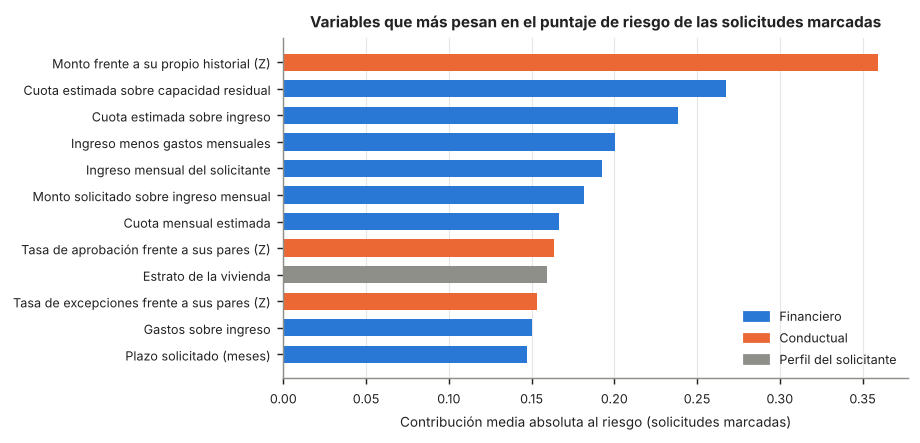

**Variables que más pesan en el puntaje de las solicitudes.** Las cinco variables con más peso en las solicitudes marcadas son: monto frente a su propio historial (Z) (9,3 %); cuota estimada sobre capacidad residual (6,9 %); cuota estimada sobre ingreso (6,2 %); ingreso menos gastos mensuales (5,2 %); ingreso mensual del solicitante (5,0 %). Por grupo de variables: financiero 58 %; conductual 30 %; perfil del solicitante 10 %; calendario 3 %. La importancia es un reparto del puntaje, no una relación causal: indica por qué el modelo marca la solicitud, no si hubo una irregularidad.

In [4]:
dv = T["dim_variable"]
sg = T["fact_shap_global"].merge(dv, on="id_variable")
sg_s = sg.sort_values("importancia_marcadas", ascending=False).reset_index(drop=True)
sg_s["pct_marcadas"] = sg_s["importancia_marcadas"] / sg_s["importancia_marcadas"].sum()
tab_sg = sg_s[["descripcion", "grupo", "importancia_marcadas", "importancia_media", "pct_marcadas"]].copy()
tab_sg.columns = ["Variable", "Grupo", "Importancia en marcadas", "Importancia en todas", "% de la importancia en marcadas"]
tab_sg["% de la importancia en marcadas"] = (100 * tab_sg["% de la importancia en marcadas"]).round(1)
tab_sg = tab_sg.round({"Importancia en marcadas": 4, "Importancia en todas": 4})
guardar_res(tab_sg, "tablero_shap_global")
display(tab_sg.head(12).style.hide(axis="index"))
print("Error máximo de aditividad (solicitudes):", f"{CTL['error_aditividad_shap_solicitud']:.2e}", "| (funcionarios):", f"{CTL['error_aditividad_shap_funcionario']:.2e}")
assert CTL["error_aditividad_shap_solicitud"] < 1e-8 and CTL["error_aditividad_shap_funcionario"] < 1e-8

grupos = sg_s.groupby("grupo")["pct_marcadas"].sum().sort_values(ascending=False)
top5 = sg_s.head(5)
fig, ax = plt.subplots(figsize=(6.2, 3.4))
t12 = sg_s.head(12).iloc[::-1]
col = {"Financiero": AZUL, "Conductual": NARANJA, "Perfil del solicitante": GRIS, "Calendario": AGUA}
ax.barh(t12["descripcion"], t12["importancia_marcadas"], color=[col[g] for g in t12["grupo"]], height=0.65)
ax.set_xlabel("Contribución media absoluta al riesgo (solicitudes marcadas)"); ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=col[g], label=g) for g in grupos.index if g in set(t12["grupo"])], loc="lower right")
ax.set_title("Variables que más pesan en el puntaje de riesgo de las solicitudes marcadas")
guardar_fig(fig, "fig_obj3_shap_solicitud")
interpretar("fig_shap_sol", "Variables que más pesan en el puntaje de las solicitudes",
            [f"Las cinco variables con más peso en las solicitudes marcadas son: " + "; ".join(f"{minus1(r.descripcion)} ({pct(r.pct_marcadas, 1)})" for r in top5.itertuples()) + ".",
             "Por grupo de variables: " + "; ".join(f"{g.lower()} {pct(v, 0)}" for g, v in grupos.items()) + ".",
             "La importancia es un reparto del puntaje, no una relación causal: indica por qué el modelo marca la solicitud, no si hubo una irregularidad."])

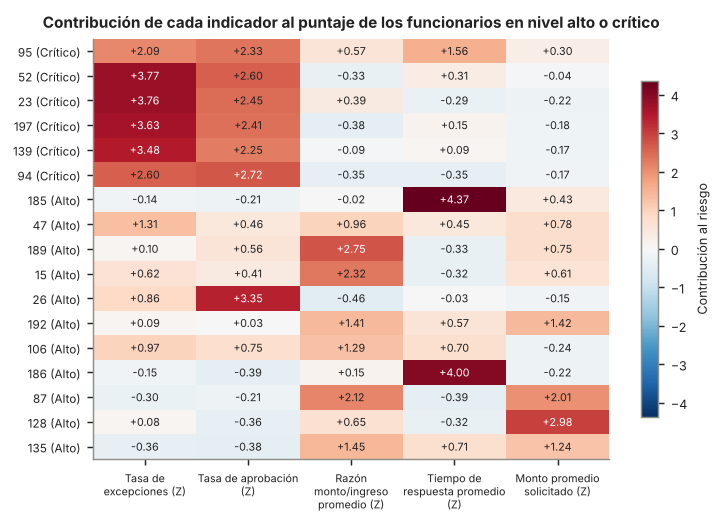

**Explicación del puntaje de los funcionarios en nivel alto o crítico.** Para los 17 funcionarios en nivel alto o crítico, el indicador que más aporta al riesgo es «tasa de excepciones frente a sus pares (Z)» en 5 de ellos. Un valor positivo (rojo) indica que el indicador del funcionario se aleja de sus pares y sube su puntaje; uno negativo (azul) lo baja. La explicación es individual: dos funcionarios con el mismo nivel pueden estar allí por indicadores distintos.

In [5]:
sf = T["fact_shap_funcionario"].merge(dv[["id_variable", "descripcion"]], on="id_variable")
marc = dfun[dfun.nivel_riesgo.isin(["Alto", "Crítico"])].merge(ff[["id_funcionario", "puntaje_riesgo"]], on="id_funcionario").sort_values("puntaje_riesgo", ascending=False)
mat_sf = (sf[sf.id_funcionario.isin(marc.id_funcionario)].pivot(index="id_funcionario", columns="descripcion", values="contribucion").reindex(marc.id_funcionario))
mat_sf = mat_sf[mat_sf.abs().mean().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.4, 4.2))
lim = np.abs(mat_sf.values).max()
im = ax.imshow(mat_sf.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
import textwrap
ax.set_xticks(range(mat_sf.shape[1])); ax.set_xticklabels(["\n".join(textwrap.wrap(c.replace(" frente a sus pares (Z)", " (Z)"), 18)) for c in mat_sf.columns], fontsize=6)
ax.set_yticks(range(mat_sf.shape[0])); ax.set_yticklabels([f"{i} ({nv})" for i, nv in zip(marc.id_funcionario, marc.nivel_riesgo)], fontsize=6.5)
ax.grid(False)
for i in range(mat_sf.shape[0]):
    for j in range(mat_sf.shape[1]):
        v = mat_sf.values[i, j]
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.6 * lim else TINTA)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("Contribución al riesgo", fontsize=7)
ax.set_title("Contribución de cada indicador al puntaje de los funcionarios en nivel alto o crítico")
guardar_fig(fig, "fig_obj3_shap_funcionarios")
frecuente = sf[sf.id_funcionario.isin(marc.id_funcionario)].sort_values("contribucion", ascending=False).groupby("id_funcionario").head(1)["descripcion"].value_counts()
interpretar("fig_shap_fun", "Explicación del puntaje de los funcionarios en nivel alto o crítico",
            [f"Para los {len(marc)} funcionarios en nivel alto o crítico, el indicador que más aporta al riesgo es «{minus1(frecuente.index[0])}» en {n(int(frecuente.iloc[0]))} de ellos.",
             f"Un valor positivo (rojo) indica que el indicador del funcionario se aleja de sus pares y sube su puntaje; uno negativo (azul) lo baja.",
             "La explicación es individual: dos funcionarios con el mismo nivel pueden estar allí por indicadores distintos."])

## 4. Modelo dimensional

El modelo es un **esquema en estrella con varias tablas de hechos** que comparten dimensiones. La granularidad de cada hecho se declara en la tabla siguiente. Las etiquetas del dataset sintético solo están en `fact_validacion_sintetica`; el resto del modelo es lo que existiría en una entidad real.

In [6]:
GRANO = {
    "fact_solicitud": ("Hecho", "Una fila por solicitud de crédito", "Medidas financieras y de gestión, puntaje de riesgo, marca y las tres variables que más pesan en el puntaje"),
    "fact_funcionario_riesgo": ("Hecho", "Una fila por funcionario", "Indicadores conductuales y financieros, puntaje, marca y tres variables que más pesan"),
    "fact_shap_funcionario": ("Hecho", "Una fila por funcionario y variable explicativa", "Contribución al riesgo y valor Z de cada indicador"),
    "fact_shap_global": ("Hecho", "Una fila por variable del modelo de solicitudes", "Importancia global de la variable en las solicitudes"),
    "fact_validacion_sintetica": ("Hecho (solo prototipo)", "Una fila por solicitud", "Etiqueta de la anomalía sintética y marca del modelo, para validar el tablero"),
    "dim_fecha": ("Dimensión", "Un día", "Año, trimestre, mes y día de la semana (2020-01-01 a 2026-12-31)"),
    "dim_funcionario": ("Dimensión", "Un funcionario", "Nivel de riesgo y marca del modelo, para segmentar"),
    "dim_producto": ("Dimensión", "Un tipo de producto financiero", "Consumo, libre inversión, hipotecario y vehículo"),
    "dim_region": ("Dimensión", "Una región", "Región de la solicitud"),
    "dim_canal": ("Dimensión", "Un canal de solicitud", "Digital, sucursal física y asesor comercial"),
    "dim_segmento": ("Dimensión", "Un segmento de cliente", "Nuevo, recurrente y preferencial"),
    "dim_estado": ("Dimensión", "Un estado de aprobación", "Aprobado, rechazado y en estudio"),
    "dim_variable": ("Dimensión", "Una variable explicativa", "Nombre legible, grupo (financiero, conductual, perfil o calendario) y nivel"),
}
mod = pd.DataFrame([(t, GRANO[t][0], GRANO[t][1], len(T[t]), TB.CLAVES_UNICAS.get(t, "id_funcionario + id_variable" if t == "fact_shap_funcionario" else "id_variable"), T[t].shape[1], GRANO[t][2]) for t in GRANO],
                   columns=["Tabla", "Tipo", "Granularidad", "Filas", "Clave", "Columnas", "Contenido"])
guardar_res(mod, "tablero_modelo_dimensional")
display(mod.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
rel = pd.DataFrame(TB.RELACIONES, columns=["Tabla de hechos (lado N)", "Columna", "Dimensión (lado 1)", "Clave"])
rel["Cardinalidad"] = "Muchos a uno"; rel["Dirección del filtro"] = "De la dimensión al hecho"
guardar_res(rel, "tablero_relaciones")
display(rel.style.hide(axis="index"))
integ = TB.integridad(T)
guardar_res(integ, "tablero_integridad")
assert (integ["Valor"] == 0).all(), "Hay filas huérfanas o claves duplicadas"
interpretar("tab_modelo", "Modelo dimensional del tablero",
            [f"El modelo tiene {sum(1 for t in GRANO if GRANO[t][0].startswith('Hecho'))} tablas de hechos y {sum(1 for t in GRANO if t.startswith('dim_'))} dimensiones, con {len(rel)} relaciones de muchos a uno.",
             f"Los {len(integ)} controles de integridad (filas sin dimensión y claves duplicadas) dan cero, de modo que ninguna solicitud ni funcionario queda fuera de un filtro por error de carga.",
             "La tabla de hechos principal tiene una fila por solicitud (" + n(len(T["fact_solicitud"])) + ") y se relaciona con seis dimensiones."])

Tabla,Tipo,Granularidad,Filas,Clave,Columnas,Contenido
fact_solicitud,Hecho,Una fila por solicitud de crédito,9500,id_solicitud,26,"Medidas financieras y de gestión, puntaje de riesgo, marca y las tres variables que más pesan en el puntaje"
fact_funcionario_riesgo,Hecho,Una fila por funcionario,220,id_funcionario,20,"Indicadores conductuales y financieros, puntaje, marca y tres variables que más pesan"
fact_shap_funcionario,Hecho,Una fila por funcionario y variable explicativa,1100,id_funcionario + id_variable,4,Contribución al riesgo y valor Z de cada indicador
fact_shap_global,Hecho,Una fila por variable del modelo de solicitudes,25,id_variable,5,Importancia global de la variable en las solicitudes
fact_validacion_sintetica,Hecho (solo prototipo),Una fila por solicitud,9500,id_solicitud,9,"Etiqueta de la anomalía sintética y marca del modelo, para validar el tablero"
dim_fecha,Dimensión,Un día,2557,id_fecha,8,"Año, trimestre, mes y día de la semana (2020-01-01 a 2026-12-31)"
dim_funcionario,Dimensión,Un funcionario,220,id_funcionario,4,"Nivel de riesgo y marca del modelo, para segmentar"
dim_producto,Dimensión,Un tipo de producto financiero,4,id_producto,2,"Consumo, libre inversión, hipotecario y vehículo"
dim_region,Dimensión,Una región,7,id_region,2,Región de la solicitud
dim_canal,Dimensión,Un canal de solicitud,3,id_canal,2,"Digital, sucursal física y asesor comercial"


Tabla de hechos (lado N),Columna,Dimensión (lado 1),Clave,Cardinalidad,Dirección del filtro
fact_solicitud,id_fecha,dim_fecha,id_fecha,Muchos a uno,De la dimensión al hecho
fact_solicitud,id_funcionario,dim_funcionario,id_funcionario,Muchos a uno,De la dimensión al hecho
fact_solicitud,id_producto,dim_producto,id_producto,Muchos a uno,De la dimensión al hecho
fact_solicitud,id_region,dim_region,id_region,Muchos a uno,De la dimensión al hecho
fact_solicitud,id_canal,dim_canal,id_canal,Muchos a uno,De la dimensión al hecho
fact_solicitud,id_segmento,dim_segmento,id_segmento,Muchos a uno,De la dimensión al hecho
fact_solicitud,id_estado,dim_estado,id_estado,Muchos a uno,De la dimensión al hecho
fact_solicitud,id_variable_1,dim_variable,id_variable,Muchos a uno,De la dimensión al hecho
fact_funcionario_riesgo,id_funcionario,dim_funcionario,id_funcionario,Muchos a uno,De la dimensión al hecho
fact_shap_funcionario,id_funcionario,dim_funcionario,id_funcionario,Muchos a uno,De la dimensión al hecho


**Modelo dimensional del tablero.** El modelo tiene 5 tablas de hechos y 8 dimensiones, con 16 relaciones de muchos a uno. Los 27 controles de integridad (filas sin dimensión y claves duplicadas) dan cero, de modo que ninguna solicitud ni funcionario queda fuera de un filtro por error de carga. La tabla de hechos principal tiene una fila por solicitud (9.500) y se relaciona con seis dimensiones.

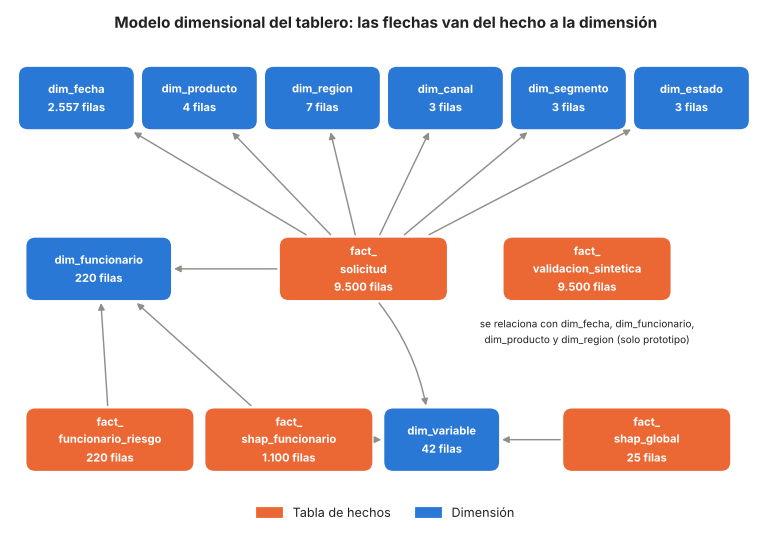

PosixPath('/home/claude/work/repo/docs/figuras/fig_obj3_modelo_dimensional.png')

In [7]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(7.4, 4.6)); ax.set_xlim(0, 100); ax.set_ylim(0, 62); ax.axis("off"); ax.grid(False)
W, H = 19, 8
POS = {"dim_fecha": (1, 50), "dim_producto": (17.5, 50), "dim_region": (34, 50), "dim_canal": (50.5, 50), "dim_segmento": (67, 50), "dim_estado": (83.5, 50),
       "dim_funcionario": (2, 27), "fact_solicitud": (36, 27), "fact_validacion_sintetica": (66, 27),
       "fact_funcionario_riesgo": (2, 4), "fact_shap_funcionario": (26, 4), "dim_variable": (50, 4), "fact_shap_global": (74, 4)}
ANCHO = {k: (W + 3 if k.startswith("fact") else 15) for k in POS}
ANCHO["dim_funcionario"] = W
def caja(k):
    x, y = POS[k]; w = ANCHO[k]
    ax.add_patch(FancyBboxPatch((x, y), w, H, boxstyle="round,pad=0.2,rounding_size=1.2", fc=NARANJA if k.startswith("fact") else AZUL, ec="none"))
    nombre = k.replace("fact_", "fact_\n", 1) if k.startswith("fact") else k
    ax.text(x + w / 2, y + H / 2, f"{nombre}\n{n(len(T[k]))} filas", ha="center", va="center", color="white", fontsize=6.2, fontweight="bold", linespacing=1.3)
def borde(k, hacia):
    # punto del borde de la caja k en dirección al centro `hacia`
    x, y = POS[k]; w = ANCHO[k]; cx, cy = x + w / 2, y + H / 2
    dx, dy = hacia[0] - cx, hacia[1] - cy
    t = min((w / 2 + 0.6) / abs(dx) if dx else 1e9, (H / 2 + 0.6) / abs(dy) if dy else 1e9)
    return (cx + dx * t, cy + dy * t)
cen = lambda k: (POS[k][0] + ANCHO[k] / 2, POS[k][1] + H / 2)
def enlace(a, b, rad=0.0):
    p, q = borde(a, cen(b)), borde(b, cen(a))
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=GRIS, lw=0.8, connectionstyle=f"arc3,rad={rad}", shrinkA=0, shrinkB=0))
for d in ["dim_fecha", "dim_producto", "dim_region", "dim_canal", "dim_segmento", "dim_estado", "dim_funcionario"]:
    enlace("fact_solicitud", d)
enlace("fact_funcionario_riesgo", "dim_funcionario"); enlace("fact_shap_funcionario", "dim_funcionario")
enlace("fact_shap_funcionario", "dim_variable"); enlace("fact_shap_global", "dim_variable"); enlace("fact_solicitud", "dim_variable", -0.12)
for k in POS: caja(k)
ax.text(POS["fact_validacion_sintetica"][0] + ANCHO["fact_validacion_sintetica"] / 2, 24.6, "se relaciona con dim_fecha, dim_funcionario,\ndim_producto y dim_region (solo prototipo)", ha="center", va="top", fontsize=5.6, color=TINTA, linespacing=1.3)
ax.legend(handles=[Patch(color=NARANJA, label="Tabla de hechos"), Patch(color=AZUL, label="Dimensión")], loc="lower center", bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=7)
ax.set_title("Modelo dimensional del tablero: las flechas van del hecho a la dimensión")
guardar_fig(fig, "fig_obj3_modelo_dimensional")

## 5. Indicadores (KPIs)

Cada indicador tiene su **fórmula en palabras**, su **medida DAX** (para pegar en Power BI) y el **valor global calculado con las mismas tablas** que carga el tablero. Los indicadores se clasifican como conductuales (cómo decide el funcionario), financieros (qué monto y qué carga implican las solicitudes), de riesgo (qué marca el modelo), de explicación y de validación (solo para el prototipo sintético). Las medidas funcionan para todo el conjunto y para cualquier segmentación (funcionario, región, producto, año), porque las relaciones propagan los filtros.

In [8]:
kp = TB.tabla_kpis()
kp["Valor global"] = [TB.KPIS_DICT[i](T) for i in kp["Id"]]
def _fmt(i, v):
    if i in ("K05", "K06", "K10", "K14", "K17", "K18"): return pct(v, 1)
    if i in ("K02", "K03"): return n(v, 0)
    if i in ("K01", "K09", "K12", "K13"): return n(v, 0)
    return n(v, 2)
kp["Valor global"] = [_fmt(i, v) for i, v in zip(kp["Id"], kp["Valor global"])]
guardar_res(kp, "tablero_kpis")
guardar_doc(kp, "tabla_kpis_tablero")
display(kp.drop(columns="Medida DAX").style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
v = dict(zip(kp["Id"], kp["Valor global"]))
interpretar("tab_kpis", "Indicadores del tablero",
            [f"El tablero reporta {len(kp)} indicadores: {n((kp.Tipo == 'Conductual').sum())} conductuales, {n((kp.Tipo == 'Financiero').sum())} financieros, {n((kp.Tipo == 'Riesgo').sum())} de riesgo, {n((kp.Tipo == 'Explicación').sum())} de explicación y {n((kp.Tipo == 'Validación').sum())} de validación.",
             f"Sobre las {v['K01']} solicitudes, la tasa de aprobación es {v['K05']}, la tasa de excepciones {v['K06']} y el tiempo de respuesta promedio {v['K07']} días; el modelo marca {v['K09']} solicitudes ({v['K10']}).",
             f"A nivel de funcionario, {v['K13']} de {v['K12']} ({v['K14']}) quedan en nivel alto o crítico."])

Id,Indicador,Tipo,Nivel,Fórmula,Valor global
K01,Total de solicitudes,Volumen,Solicitud,Número de solicitudes del contexto de filtro,9.500
K02,Monto solicitado total (COP),Financiero,Solicitud,Suma del monto solicitado,261.405.253.229
K03,Monto solicitado promedio (COP),Financiero,Solicitud,Promedio del monto solicitado,27.516.342
K04,Razón monto/ingreso mediana,Financiero,Solicitud,Mediana de monto solicitado / ingreso mensual,"5,10"
K05,Tasa de aprobación,Conductual,Solicitud,Solicitudes aprobadas / total de solicitudes,"71,5 %"
K06,Tasa de excepciones,Conductual,Solicitud,Solicitudes con excepción a políticas / total de solicitudes,"9,0 %"
K07,Tiempo de respuesta promedio (días),Conductual,Solicitud,Promedio de días de respuesta,"9,31"
K08,Tiempo de respuesta P90 (días),Conductual,Solicitud,Percentil 90 de los días de respuesta,"15,00"
K09,Solicitudes marcadas,Riesgo,Solicitud,"Solicitudes con puntaje en el 7,5 % superior del entrenamiento",734
K10,% de solicitudes marcadas,Riesgo,Solicitud,Solicitudes marcadas / total de solicitudes,"7,7 %"


**Indicadores del tablero.** El tablero reporta 18 indicadores: 4 conductuales, 3 financieros, 6 de riesgo, 1 de explicación y 2 de validación. Sobre las 9.500 solicitudes, la tasa de aprobación es 71,5 %, la tasa de excepciones 9,0 % y el tiempo de respuesta promedio 9,31 días; el modelo marca 734 solicitudes (7,7 %). A nivel de funcionario, 17 de 220 (7,7 %) quedan en nivel alto o crítico.

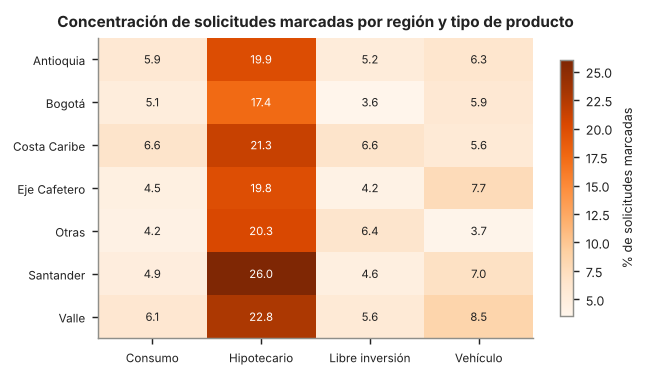

**Concentración de solicitudes marcadas.** El porcentaje de solicitudes marcadas va de 3,6 % (Bogotá, libre inversión) a 26,0 % (Santander, hipotecario); el global es 7,7 %. Por tipo de producto, el promedio va de 5,2 % (libre inversión) a 21,1 % (hipotecario); por región, de 8,0 % a 10,7 %. El producto con más marcas es también el de mayor monto solicitado promedio, de modo que el modelo tiende a marcar montos altos; conviene leer el puntaje dentro de cada producto. Con pocas solicitudes por celda, las diferencias pequeñas pueden deberse al azar; el mapa sirve para priorizar la revisión y no para concluir sobre una región o un producto.

In [9]:
# Concentración de alertas: % de solicitudes marcadas por región y tipo de producto (mapa de calor de la página 2 del tablero)
cr = (fs.merge(T["dim_region"], on="id_region").merge(T["dim_producto"], on="id_producto")
        .pivot_table(index="region", columns="tipo_producto_financiero", values="marcada", aggfunc="mean") * 100)
guardar_res(cr.round(2).reset_index(), "tablero_mapa_calor_region_producto")
fig, ax = plt.subplots(figsize=(5.4, 3.0))
im = ax.imshow(cr.values, cmap="Oranges", aspect="auto"); ax.grid(False)
ax.set_xticks(range(cr.shape[1])); ax.set_xticklabels(cr.columns, fontsize=6.5); ax.set_yticks(range(cr.shape[0])); ax.set_yticklabels(cr.index, fontsize=6.5)
for i in range(cr.shape[0]):
    for j in range(cr.shape[1]):
        ax.text(j, i, f"{cr.values[i, j]:.1f}", ha="center", va="center", fontsize=6.3, color="white" if cr.values[i, j] > cr.values.mean() + cr.values.std() else TINTA)
cb = fig.colorbar(im, ax=ax, shrink=0.85); cb.set_label("% de solicitudes marcadas", fontsize=7)
ax.set_title("Concentración de solicitudes marcadas por región y tipo de producto")
guardar_fig(fig, "fig_obj3_mapa_calor")
mx = np.unravel_index(cr.values.argmax(), cr.shape); mn = np.unravel_index(cr.values.argmin(), cr.shape)
interpretar("fig_calor", "Concentración de solicitudes marcadas",
            [f"El porcentaje de solicitudes marcadas va de {n(cr.values.min(), 1)} % ({cr.index[mn[0]]}, {cr.columns[mn[1]].lower()}) a {n(cr.values.max(), 1)} % ({cr.index[mx[0]]}, {cr.columns[mx[1]].lower()}); el global es {pct(fs.marcada.mean(), 1)}.",
             f"Por tipo de producto, el promedio va de {n(cr.mean().min(), 1)} % ({cr.mean().idxmin().lower()}) a {n(cr.mean().max(), 1)} % ({cr.mean().idxmax().lower()}); por región, de {n(cr.mean(axis=1).min(), 1)} % a {n(cr.mean(axis=1).max(), 1)} %.",
             ("El producto con más marcas es también el de mayor monto solicitado promedio, de modo que el modelo tiende a marcar montos altos; conviene leer el puntaje dentro de cada producto." if fs.merge(T["dim_producto"], on="id_producto").groupby("tipo_producto_financiero")["monto_solicitado"].mean().idxmax() == cr.mean().idxmax() else "El producto con más marcas no es el de mayor monto solicitado promedio."),
             "Con pocas solicitudes por celda, las diferencias pequeñas pueden deberse al azar; el mapa sirve para priorizar la revisión y no para concluir sobre una región o un producto."])

## 6. Validación de totales: fuente frente a tablero

La validación compara el valor de cada control en la **fuente** (archivos del repositorio: `dataset_creditos_sinteticos.csv`, `solicitudes_limpias.csv`, `matriz_solicitud.csv`, `perfil_funcionario.csv`) con el valor calculado desde las **tablas del tablero**, leídas de los CSV exportados (viaje de ida y vuelta, no de la memoria). La diferencia esperada es cero. El archivo `dashboard/Validacion_totales_tablero.xlsx` tiene una columna vacía, **«Valor en Power BI»**, para que el equipo escriba lo que muestre el tablero; la diferencia y el resultado se calculan con fórmulas.

In [10]:
TB.exportar(T, DASH)
T_csv = {k: pd.read_csv(DASH / f"{k}.csv", encoding="utf-8-sig") for k in T}
VAL = TB.validacion_totales(T_csv, ROOT, T_ref=T)
guardar_res(VAL, "tablero_validacion_totales")
guardar_doc(VAL.drop(columns="valor_power_bi"), "tabla_validacion_totales")
vis = VAL.copy()
vis["valor_fuente"] = vis["valor_fuente"].map(lambda x: f"{x:,.4f}".rstrip("0").rstrip(".")); vis["valor_tablero_python"] = vis["valor_tablero_python"].map(lambda x: f"{x:,.4f}".rstrip("0").rstrip("."))
vis["diferencia"] = VAL["diferencia"].map(lambda x: f"{x:.2g}")
display(vis.drop(columns=["valor_power_bi"]).style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
cubiertos = {c.split()[1] for c in VAL.control if c.startswith("KPI ")}
assert set(kp["Id"]) <= cubiertos, f"KPIs sin control de validación: {sorted(set(kp['Id']) - cubiertos)}"
n_ok = int((VAL.resultado == "Coincide").sum())
assert n_ok == len(VAL), "Hay controles de totales que no coinciden"
interpretar("tab_validacion", "Validación de totales entre la fuente y las tablas del tablero",
            [f"De {len(VAL)} controles, {n(n_ok)} coinciden con la fuente; la mayor diferencia absoluta es {VAL['diferencia'].abs().max():.2g}.",
             f"Los controles cubren los registros de cada tabla de hechos, los {len(kp)} indicadores (K01 a K{len(kp):02d}) y los desgloses por región, producto, canal, estado y año.",
             "Falta el último paso, que solo puede hacer el equipo: escribir en el archivo de Excel los valores que muestre Power BI y comprobar que la diferencia sea cero."])

control,medida,fuente,valor_fuente,valor_tablero_python,diferencia,resultado
Registros,fact_solicitud,Filas de dataset_creditos_sinteticos.csv,"9,500","9,500",0,Coincide
Registros,fact_funcionario_riesgo,Funcionarios distintos en la matriz,220,220,0,Coincide
Registros,fact_validacion_sintetica,Filas de etiquetas_evaluacion.csv,"9,500","9,500",0,Coincide
Registros,fact_shap_funcionario,Funcionarios × variables del nivel funcionario,"1,100","1,100",0,Coincide
Registros,dim_fecha,Días entre 2020-01-01 y 2026-12-31,"2,557","2,557",0,Coincide
KPI K01,Total de solicitudes,Filas de solicitudes_limpias.csv,"9,500","9,500",0,Coincide
KPI K02,Monto solicitado total (COP),Suma de monto_solicitado en solicitudes_limpias.csv,"261,405,253,229","261,405,253,229",0,Coincide
KPI K03,Monto solicitado promedio (COP),Promedio de monto_solicitado en solicitudes_limpias.csv,"27,516,342.4452","27,516,342.4452",0,Coincide
KPI K04,Razón monto/ingreso mediana,Mediana de monto / ingreso en matriz_solicitud.csv,5.0977,5.0977,0,Coincide
KPI K05,Tasa de aprobación,Solicitudes 'Aprobado' / total en solicitudes_limpias.csv,0.7153,0.7153,0,Coincide


**Validación de totales entre la fuente y las tablas del tablero.** De 51 controles, 51 coinciden con la fuente; la mayor diferencia absoluta es 4.9e-07. Los controles cubren los registros de cada tabla de hechos, los 18 indicadores (K01 a K18) y los desgloses por región, producto, canal, estado y año. Falta el último paso, que solo puede hacer el equipo: escribir en el archivo de Excel los valores que muestre Power BI y comprobar que la diferencia sea cero.

In [11]:
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
wb = Workbook(); ws = wb.active; ws.title = "Validación de totales"
enc = ["Control", "Medida", "Fuente", "Valor en la fuente", "Valor en las tablas del tablero (Python)", "Diferencia (Python)", "Resultado (Python)", "Valor en Power BI (digitar)", "Diferencia con Power BI", "Resultado con Power BI"]
ws.append(enc)
for i, r in enumerate(VAL.itertuples(index=False), start=2):
    ws.append([r.control, r.medida, r.fuente, r.valor_fuente, r.valor_tablero_python, f"=E{i}-D{i}", f'=IF(ABS(F{i})<=0.000001*MAX(1,ABS(D{i})),"Coincide","Revisar")', None,
               f'=IF(H{i}="","",H{i}-D{i})', f'=IF(H{i}="","Pendiente",IF(ABS(I{i})<=0.000001*MAX(1,ABS(D{i})),"Coincide","Revisar"))'])
borde = Side(style="thin", color="DDDDDD")
for c in ws[1]:
    c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="2A78D6"); c.alignment = Alignment(wrap_text=True, vertical="center")
for fila in ws.iter_rows(min_row=2):
    for c in fila:
        c.border = Border(bottom=borde)
        if c.column in (4, 5, 6, 8, 9):
            v0 = fila[3].value
            c.number_format = "#,##0" if (isinstance(v0, (int, float)) and float(v0).is_integer()) else "#,##0.000000"
    fila[7].fill = PatternFill("solid", fgColor="FFF4D6")
for col, ancho in zip("ABCDEFGHIJ", (24, 44, 52, 20, 22, 16, 16, 20, 18, 20)):
    ws.column_dimensions[col].width = ancho
ws.row_dimensions[1].height = 32; ws.freeze_panes = "A2"
ws2 = wb.create_sheet("Integridad")
ws2.append(["Control de integridad", "Valor", "Esperado"])
for r in integ.itertuples(index=False): ws2.append([r[0], int(r[1]), 0])
for c in ws2[1]: c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="2A78D6")
ws2.column_dimensions["A"].width = 70
ws3 = wb.create_sheet("Cómo usar")
for linea in ["1. En Power BI, cree una tarjeta o una tabla con la medida indicada en la columna «Medida» (las medidas DAX están en dashboard/GUIA_POWER_BI.md).",
              "2. Sin ningún filtro activo, escriba el valor que muestra Power BI en la columna H («Valor en Power BI»).",
              "3. Las columnas I y J se calculan solas: la diferencia esperada es cero y el resultado debe decir «Coincide».",
              "4. Para los desgloses (región, producto, canal, estado y año), use una tabla con la dimensión en las filas y la medida «Total de solicitudes».",
              "5. Si un control dice «Revisar», revise primero las relaciones del modelo (todas de muchos a uno, filtro de la dimensión al hecho) y los tipos de dato."]:
    ws3.append([linea])
ws3.column_dimensions["A"].width = 130
wb.save(GUIA / "Validacion_totales_tablero.xlsx")
print("Libro de validación guardado:", (GUIA / "Validacion_totales_tablero.xlsx").name, "|", len(VAL), "controles")

Libro de validación guardado: Validacion_totales_tablero.xlsx | 51 controles


In [12]:
(GUIA / "GUIA_POWER_BI.md").write_text(TB.guia_markdown(T, CTL), encoding="utf-8")
print("Guía guardada:", "dashboard/GUIA_POWER_BI.md", "|", len((GUIA / "GUIA_POWER_BI.md").read_text(encoding="utf-8").splitlines()), "líneas")

Guía guardada: dashboard/GUIA_POWER_BI.md | 211 líneas


## 7. Validación con la verdad sintética (solo para el prototipo)

Como los datos son sintéticos, se conoce qué solicitudes y qué funcionarios son atípicos. Esa verdad **no entra al modelo ni a las tablas operativas**; solo sirve para comprobar que el tablero pone en revisión lo que debe. En una entidad real esta página no existiría.

In [13]:
from sklearn.metrics import average_precision_score, roc_auc_score
yv = valid["es_anomalia"].values
def met(mask):
    vp = int(((valid.marcada == 1) & (valid.es_anomalia == 1))[mask].sum()); mar = int(valid.marcada[mask].sum()); pos = int(valid.es_anomalia[mask].sum())
    p = vp / mar if mar else np.nan; r = vp / pos if pos else np.nan
    return dict(Solicitudes=int(mask.sum()), Anómalas=pos, Marcadas=mar, Aciertos=vp, Precisión=p, Recall=r, F1=2 * p * r / (p + r) if (p + r) else np.nan)
fila = []
for nom, mask in [("Entrenamiento", valid.particion == "Entrenamiento"), ("Prueba", valid.particion == "Prueba"), ("Total", valid.particion.notna())]:
    d = met(mask.values); d["Conjunto"] = nom
    sc = fs.score_modelo.values[mask.values]; d["AUC-PR"] = average_precision_score(yv[mask.values], sc); d["AUC-ROC"] = roc_auc_score(yv[mask.values], sc)
    fila.append(d)
vs = pd.DataFrame(fila)[["Conjunto", "Solicitudes", "Anómalas", "Marcadas", "Aciertos", "Precisión", "Recall", "F1", "AUC-PR", "AUC-ROC"]]
guardar_res(vs.round(4), "tablero_validacion_sintetica")
display(vs.style.hide(axis="index").format({c: "{:.3f}" for c in ["Precisión", "Recall", "F1", "AUC-PR", "AUC-ROC"]}))

# por tipo de anomalía: proporción marcada (en las solicitudes de la prueba y normales)
tipo = valid.assign(Tipo=valid.tipo_anomalia).groupby("Tipo").agg(Solicitudes=("marcada", "size"), Marcadas=("marcada", "sum"))
tipo["% marcadas"] = (100 * tipo.Marcadas / tipo.Solicitudes).round(1)
tipo = tipo.reset_index(); guardar_res(tipo, "tablero_validacion_por_tipo")
display(tipo.style.hide(axis="index"))

# nivel de funcionario frente a la verdad
ef = pd.read_csv(PROC / "etiquetas_evaluacion_funcionario.csv", encoding="utf-8-sig")
cf = dfun.merge(ef, left_on="id_funcionario", right_on="id_funcionario_evaluador")
tabf = pd.crosstab(cf.nivel_riesgo, cf.funcionario_atipico.map({0: "No atípico", 1: "Atípico"})).reindex(["Crítico", "Alto", "Medio", "Bajo"]).fillna(0).astype(int).reset_index().rename(columns={"nivel_riesgo": "Nivel de riesgo"})
for c in ("Atípico", "No atípico"):
    if c not in tabf: tabf[c] = 0
guardar_res(tabf, "tablero_validacion_funcionarios")
display(tabf.style.hide(axis="index"))

# comparación con el cuaderno 02 (misma partición de prueba)
rp = pd.read_csv(RT2 / "resultados_prueba.csv", encoding="utf-8-sig").set_index("modelo")
f1_nb2 = float(rp.loc["isolation_forest", "f1_anomalia"]) if "isolation_forest" in rp.index else float("nan")
pr, tr = vs.set_index("Conjunto").loc["Prueba"], vs.set_index("Conjunto").loc["Entrenamiento"]
atip_crit = int(tabf.loc[tabf["Nivel de riesgo"] == "Crítico", "Atípico"].sum()); n_atip = int(tabf["Atípico"].sum())
falsos_alto = int(tabf.loc[tabf["Nivel de riesgo"].isin(["Crítico", "Alto"]), "No atípico"].sum())
interpretar("tab_verdad", "Validación del puntaje con la verdad sintética",
            [f"En la prueba, el puntaje marca {n(int(pr.Marcadas))} solicitudes y acierta {n(int(pr.Aciertos))} de las {n(int(pr.Anómalas))} anómalas: precisión {n(pr.Precisión, 3)}, recall {n(pr.Recall, 3)} y F1 {n(pr.F1, 3)}; el cuaderno 02 obtiene un F1 de {n(f1_nb2, 3)} con Isolation Forest ajustado.",
             f"El F1 es {n(tr.F1, 3)} en entrenamiento y {n(pr.F1, 3)} en prueba" + ("; la diferencia es menor de 0,05, sin señal de sobreajuste en un detector que no ve la etiqueta." if abs(tr.F1 - pr.F1) < 0.05 else "; la diferencia es de 0,05 o más y debe revisarse."),
             f"A nivel de funcionario, {n(atip_crit)} de los {n(n_atip)} atípicos quedan en nivel crítico y {n(falsos_alto)} funcionarios no atípicos están en nivel alto o crítico; con solo {n_atip} casos positivos, esto es descriptivo y no una prueba de desempeño.",
             "El perfil de funcionario usa todas las solicitudes y los puntajes Z se calculan con los 220 funcionarios como referencia; en el cuaderno 02 la referencia de pares se calcula solo con el entrenamiento, así que las cifras de funcionario no son comparables una a una."])

Conjunto,Solicitudes,Anómalas,Marcadas,Aciertos,Precisión,Recall,F1,AUC-PR,AUC-ROC
Entrenamiento,6650,530,499,208,0.417,0.392,0.404,0.397,0.866
Prueba,2850,227,235,88,0.374,0.388,0.381,0.355,0.855
Total,9500,757,734,296,0.403,0.391,0.397,0.383,0.862


Tipo,Solicitudes,Marcadas,% marcadas
Funcionario con aprobación atípica,254,86,33.900000
Monto desproporcionado vs. ingreso,249,162,65.100000
Ninguna,8743,438,5.000000
Tiempo de respuesta excesivo,254,48,18.900000


Nivel de riesgo,Atípico,No atípico
Crítico,6,0
Alto,0,11
Medio,0,38
Bajo,0,165


**Validación del puntaje con la verdad sintética.** En la prueba, el puntaje marca 235 solicitudes y acierta 88 de las 227 anómalas: precisión 0,374, recall 0,388 y F1 0,381; el cuaderno 02 obtiene un F1 de 0,432 con Isolation Forest ajustado. El F1 es 0,404 en entrenamiento y 0,381 en prueba; la diferencia es menor de 0,05, sin señal de sobreajuste en un detector que no ve la etiqueta. A nivel de funcionario, 6 de los 6 atípicos quedan en nivel crítico y 11 funcionarios no atípicos están en nivel alto o crítico; con solo 6 casos positivos, esto es descriptivo y no una prueba de desempeño. El perfil de funcionario usa todas las solicitudes y los puntajes Z se calculan con los 220 funcionarios como referencia; en el cuaderno 02 la referencia de pares se calcula solo con el entrenamiento, así que las cifras de funcionario no son comparables una a una.

## 8. Sensibilidad: variables del puntaje de solicitud

El tablero usa las variables del apartado 8.4.3. Se compara con el conjunto completo del cuaderno 02 (que agrega calendario, rezagos y ventanas móviles) para ver si la elección cambia el desempeño y la explicación. No se elige por el resultado: se elige por interpretabilidad, y esta tabla documenta lo que se pierde o se gana.

In [14]:
def corrida(fe):
    Tn, cn = TB.calcular(ROOT, fe=fe)
    v = Tn["fact_validacion_sintetica"]; p = v[v.particion == "Prueba"]
    vp = int(((p.marcada == 1) & (p.es_anomalia == 1)).sum()); pr_ = vp / p.marcada.sum(); rc = vp / p.es_anomalia.sum()
    sc = Tn["fact_solicitud"].score_modelo.values[(Tn["fact_solicitud"].particion == "Prueba").values]
    g = Tn["fact_shap_global"].merge(Tn["dim_variable"], on="id_variable").sort_values("importancia_marcadas", ascending=False)
    gr = g.groupby("grupo")["importancia_marcadas"].sum(); gr = gr / gr.sum()
    return {"Variables": len(cn["variables_modelo"]), "Precisión (prueba)": pr_, "Recall (prueba)": rc, "F1 (prueba)": 2 * pr_ * rc / (pr_ + rc), "AUC-PR (prueba)": average_precision_score(p.es_anomalia.values, sc),
            "Variable que más pesa": g.iloc[0]["descripcion"], "% de importancia en variables de calendario": 100 * float(gr.get("Calendario", 0.0))}
sens = pd.DataFrame({"Conjunto de variables": ["Apartado 8.4.3 (usado en el tablero)", "Conjunto completo del cuaderno 02"], **pd.DataFrame([corrida("8.4.3"), corrida(True)]).to_dict("list")})
guardar_res(sens.round(4), "tablero_sensibilidad_variables")
display(sens.style.hide(axis="index").format({"Precisión (prueba)": "{:.3f}", "Recall (prueba)": "{:.3f}", "F1 (prueba)": "{:.3f}", "AUC-PR (prueba)": "{:.3f}", "% de importancia en variables de calendario": "{:.1f}"}))
a, b = sens.iloc[0], sens.iloc[1]
interpretar("tab_sens", "Sensibilidad del puntaje al conjunto de variables",
            [f"Con las variables del apartado 8.4.3 el F1 en la prueba es {n(a['F1 (prueba)'], 3)}; con el conjunto completo, {n(b['F1 (prueba)'], 3)}.",
             f"En el conjunto completo la variable que más pesa es «{minus1(b['Variable que más pesa'])}» y las variables de calendario concentran {n(b['% de importancia en variables de calendario'], 1)} % de la importancia; con 8.4.3 la que más pesa es «{minus1(a['Variable que más pesa'])}».",
             "Un analista de control interno interpreta con más facilidad una explicación basada en montos, ingresos y comparación con pares que una basada en el día del mes, por eso el tablero usa el conjunto del apartado 8.4.3."])

Conjunto de variables,Variables,Precisión (prueba),Recall (prueba),F1 (prueba),AUC-PR (prueba),Variable que más pesa,% de importancia en variables de calendario
Apartado 8.4.3 (usado en el tablero),25,0.374,0.388,0.381,0.355,Monto frente a su propio historial (Z),2.5
Conjunto completo del cuaderno 02,37,0.410,0.414,0.412,0.410,Solicitud en los últimos días del mes,14.7


**Sensibilidad del puntaje al conjunto de variables.** Con las variables del apartado 8.4.3 el F1 en la prueba es 0,381; con el conjunto completo, 0,412. En el conjunto completo la variable que más pesa es «solicitud en los últimos días del mes» y las variables de calendario concentran 14,7 % de la importancia; con 8.4.3 la que más pesa es «monto frente a su propio historial (Z)». Un analista de control interno interpreta con más facilidad una explicación basada en montos, ingresos y comparación con pares que una basada en el día del mes, por eso el tablero usa el conjunto del apartado 8.4.3.

## 9. Exportación y comprobaciones finales

In [15]:
# Si alguna falla, el cuaderno se detiene
assert len(fs) == 9500 and fs.id_solicitud.is_unique
assert set(fs.particion) == {"Entrenamiento", "Prueba"} and (fs.particion == "Entrenamiento").sum() == CTL["n_entrenamiento"]
assert not any(c in fs.columns for c in ("es_anomalia", "tipo_anomalia")), "Una etiqueta quedó en la tabla operativa"
assert not any(c in T["fact_funcionario_riesgo"].columns for c in ("funcionario_atipico", "es_anomalia"))
assert (VAL.resultado == "Coincide").all() and (integ.Valor == 0).all()
assert (DASH / "fact_solicitud.csv").exists() and (GUIA / "Validacion_totales_tablero.xlsx").exists() and (GUIA / "GUIA_POWER_BI.md").exists()
assert dfun.nivel_riesgo.isin(["Bajo", "Medio", "Alto", "Crítico"]).all() and int(dfun.marcado_modelo.sum()) == int(dfun.nivel_riesgo.isin(["Alto", "Crítico"]).sum())
RESULTADOS["tablas_dashboard"] = sorted(p.name for p in DASH.glob("*.csv"))
RESULTADOS["figuras_generadas"] = sorted(p.name for p in FIG.glob("fig_obj3_*.png"))
RESULTADOS["tablas_resultados"] = sorted(p.name for p in RT.glob("tablero_*.csv"))
RESULTADOS["control"] = {k: v for k, v in CTL.items() if k != "variables_modelo"}
RESULTADOS["n_controles_validacion"] = int(len(VAL))
(RES / "resultados_obj3.json").write_text(json.dumps(RESULTADOS, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
print("Todas las comprobaciones pasaron.")
print(len(RESULTADOS["tablas_dashboard"]), "tablas para Power BI en data/dashboard,", len(RESULTADOS["tablas_resultados"]), "tablas de resultados y", len(RESULTADOS["figuras_generadas"]), "figuras.")

Todas las comprobaciones pasaron.
13 tablas para Power BI en data/dashboard, 14 tablas de resultados y 4 figuras.


## 10. Bitácora de decisiones del objetivo 3

Las decisiones marcadas como **supuesto** se tomaron para poder avanzar y están pendientes de confirmación.

In [16]:
bit3 = pd.DataFrame([
    ("2026-11-16", "Alimentar el tablero con Isolation Forest sin etiquetas y con configuración fijada de antemano (200 árboles, 256 muestras, contaminación 7,5 %).", "Usar el mejor modelo del cuaderno 02 (con hiperparámetros ajustados con la etiqueta); usar un modelo supervisado.", "El informe dice que el tablero se alimenta con la salida del mejor modelo de la fase 5, pero esa elección depende de la respuesta pendiente sobre el uso de etiquetas. Isolation Forest da un puntaje continuo, tiene explicación SHAP exacta y no depende de esa decisión.", "src/tablero.py (CONFIG_SOLICITUD)", "Supuesto: confirmar con el tutor y el profesor"),
    ("2026-11-16", "El puntaje de solicitud usa las variables del apartado 8.4.3 y no el conjunto completo del cuaderno 02.", "Usar el conjunto completo con calendario, rezagos y ventanas móviles.", "El profesor sugirió las variables de 8.4.3; además, con el conjunto completo la explicación SHAP queda dominada por una variable de calendario (día del mes), difícil de interpretar para control interno. La sección 8 documenta la diferencia de desempeño.", "Sección 8", "Supuesto: confirmar con el tutor"),
    ("2026-11-16", "Nivel de riesgo del funcionario por cortes del puntaje de anomalía: crítico desde el cuantil 97,5 %, alto desde el 92,5 %, medio desde el 75 %.", "Cortes fijos por valor del puntaje; solo marca binaria.", "Permite priorizar la revisión en cuatro niveles; el corte de 92,5 % coincide con la contaminación de 7,5 % usada en el resto del proyecto. Son cortes de diseño, no resultados del modelo.", "Sección 2", "Propuesta: revisar con el equipo"),
    ("2026-11-16", "Perfil de funcionario con todas las solicitudes y puntajes Z con los 220 funcionarios como referencia.", "Perfil solo con las solicitudes de entrenamiento (como en la evaluación del cuaderno 02).", "El tablero monitorea a todos los funcionarios con la información disponible; el modelo no ve etiquetas, por lo que no hay fuga. Las cifras de funcionario no son comparables una a una con las del cuaderno 02 y así se declara.", "Sección 2 y 7", "Adoptada"),
    ("2026-11-16", "Etiquetas sintéticas solo en fact_validacion_sintetica.", "Incluirlas en las tablas operativas para colorear los visuales.", "Mantiene el tablero como lo vería una entidad real y evita que una etiqueta se filtre a un visual operativo; la página de validación es explícita sobre su carácter sintético.", "Sección 4 y 7", "Adoptada"),
    ("2026-11-16", "Explicación con valores SHAP exactos para árboles (TreeExplainer), con comprobación de aditividad.", "Importancia por permutación; explicación solo global.", "El informe (fase 6) define SHAP; la aditividad (error del orden de 1e-13) garantiza que la explicación reproduce el puntaje.", "Sección 3", "Adoptada"),
    ("2026-11-16", "Modelo en estrella con varias tablas de hechos (solicitud, funcionario, explicación, validación) y dimensiones compartidas.", "Una sola tabla plana como en el prototipo de septiembre.", "La lista técnica pide hechos y dimensiones; las relaciones muchos a uno con filtro de la dimensión al hecho evitan ambigüedad en DAX.", "Sección 4", "Adoptada"),
    ("2026-11-16", "El archivo .pbix lo arma el equipo; este cuaderno entrega tablas, medidas DAX, guía y validación de totales.", "Generar el .pbix desde el código.", "Power BI Desktop no se puede ejecutar desde este entorno; las medidas DAX se verifican con su equivalente en Python, pero la verificación final la hace el equipo con la hoja «Validación de totales».", "dashboard/", "Pendiente del equipo"),
], columns=["Fecha", "Decisión", "Alternativas", "Justificación", "Evidencia", "Estado"])
guardar_doc(bit3, "tabla_bitacora_decisiones_obj3")
display(bit3.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Fecha,Decisión,Alternativas,Justificación,Evidencia,Estado
2026-11-16,"Alimentar el tablero con Isolation Forest sin etiquetas y con configuración fijada de antemano (200 árboles, 256 muestras, contaminación 7,5 %).",Usar el mejor modelo del cuaderno 02 (con hiperparámetros ajustados con la etiqueta); usar un modelo supervisado.,"El informe dice que el tablero se alimenta con la salida del mejor modelo de la fase 5, pero esa elección depende de la respuesta pendiente sobre el uso de etiquetas. Isolation Forest da un puntaje continuo, tiene explicación SHAP exacta y no depende de esa decisión.",src/tablero.py (CONFIG_SOLICITUD),Supuesto: confirmar con el tutor y el profesor
2026-11-16,El puntaje de solicitud usa las variables del apartado 8.4.3 y no el conjunto completo del cuaderno 02.,"Usar el conjunto completo con calendario, rezagos y ventanas móviles.","El profesor sugirió las variables de 8.4.3; además, con el conjunto completo la explicación SHAP queda dominada por una variable de calendario (día del mes), difícil de interpretar para control interno. La sección 8 documenta la diferencia de desempeño.",Sección 8,Supuesto: confirmar con el tutor
2026-11-16,"Nivel de riesgo del funcionario por cortes del puntaje de anomalía: crítico desde el cuantil 97,5 %, alto desde el 92,5 %, medio desde el 75 %.",Cortes fijos por valor del puntaje; solo marca binaria.,"Permite priorizar la revisión en cuatro niveles; el corte de 92,5 % coincide con la contaminación de 7,5 % usada en el resto del proyecto. Son cortes de diseño, no resultados del modelo.",Sección 2,Propuesta: revisar con el equipo
2026-11-16,Perfil de funcionario con todas las solicitudes y puntajes Z con los 220 funcionarios como referencia.,Perfil solo con las solicitudes de entrenamiento (como en la evaluación del cuaderno 02).,"El tablero monitorea a todos los funcionarios con la información disponible; el modelo no ve etiquetas, por lo que no hay fuga. Las cifras de funcionario no son comparables una a una con las del cuaderno 02 y así se declara.",Sección 2 y 7,Adoptada
2026-11-16,Etiquetas sintéticas solo en fact_validacion_sintetica.,Incluirlas en las tablas operativas para colorear los visuales.,Mantiene el tablero como lo vería una entidad real y evita que una etiqueta se filtre a un visual operativo; la página de validación es explícita sobre su carácter sintético.,Sección 4 y 7,Adoptada
2026-11-16,"Explicación con valores SHAP exactos para árboles (TreeExplainer), con comprobación de aditividad.",Importancia por permutación; explicación solo global.,El informe (fase 6) define SHAP; la aditividad (error del orden de 1e-13) garantiza que la explicación reproduce el puntaje.,Sección 3,Adoptada
2026-11-16,"Modelo en estrella con varias tablas de hechos (solicitud, funcionario, explicación, validación) y dimensiones compartidas.",Una sola tabla plana como en el prototipo de septiembre.,La lista técnica pide hechos y dimensiones; las relaciones muchos a uno con filtro de la dimensión al hecho evitan ambigüedad en DAX.,Sección 4,Adoptada
2026-11-16,"El archivo .pbix lo arma el equipo; este cuaderno entrega tablas, medidas DAX, guía y validación de totales.",Generar el .pbix desde el código.,"Power BI Desktop no se puede ejecutar desde este entorno; las medidas DAX se verifican con su equivalente en Python, pero la verificación final la hace el equipo con la hoja «Validación de totales».",dashboard/,Pendiente del equipo
